# Practical: Email Spam Classification with KNN and SVM

## Objective

Classify each email as normal (not spam, label 0) or spam (label 1) using K-Nearest Neighbors and a Support Vector Machine. Compare both models with accuracy, precision, recall, F1-score, and confusion matrices.

## Dataset

The Kaggle file is a pre-tokenized bag-of-words table. It contains an Email No. identifier, word-frequency columns, and the Prediction target. The identifier is not a predictive feature. The notebook transforms word counts to TF-IDF inside each model pipeline so the transformation is learned from training data only.

Download emails.csv from the Kaggle source linked in the repository README and place it at Data/emails.csv.

In [1]:
%matplotlib inline

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH = Path("Data/emails.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place the Kaggle emails.csv file at Data/emails.csv (see the repository README)."
    )

## 1. Load and inspect the dataset

Check the table dimensions, missing values, duplicate rows, and target balance before training.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("First columns:", list(df.columns[:8]))
print("Target column:", df.columns[-1])
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Target counts:")
print(df["Prediction"].value_counts().sort_index().rename(index={0: "Not spam", 1: "Spam"}))

# Display a small preview of the numeric word-count representation.
display(df.iloc[:5, :8])

Dataset shape: (5172, 3002)
First columns: ['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a']
Target column: Prediction
Missing values: 0


Duplicate rows: 0
Target counts:
Prediction
Not spam    3672
Spam        1500
Name: count, dtype: int64


,Email No.,the,to,ect,and,for,of,a
0,Email 1,0,0,1,0,0,0,2
1,Email 2,8,13,24,6,6,2,102
2,Email 3,0,0,1,0,0,0,8
3,Email 4,0,5,22,0,5,1,51
4,Email 5,7,6,17,1,5,2,57


## 2. Pre-process the data

Remove duplicate records, exclude the row identifier, coerce word counts to numeric values, and keep the two documented target labels. The split is stratified to preserve the class balance.

In [3]:
df = df.dropna(subset=["Prediction"]).drop_duplicates().copy()
y = pd.to_numeric(df["Prediction"], errors="coerce")
valid_target = y.isin([0, 1])
df = df.loc[valid_target].copy()
y = y.loc[valid_target].astype("int8")

id_columns = [column for column in ["Email No."] if column in df.columns]
X_frame = df.drop(columns=id_columns + ["Prediction"])
X_frame = X_frame.apply(pd.to_numeric, errors="coerce").fillna(0).clip(lower=0)

X = csr_matrix(X_frame.to_numpy(dtype=np.float32))
print("Rows after cleaning:", X.shape[0])
print("Word-count features:", X.shape[1])
print("Class counts (0 = not spam, 1 = spam):")
print(y.value_counts().sort_index().to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y.to_numpy(), test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Rows after cleaning: 5172
Word-count features: 3000
Class counts (0 = not spam, 1 = spam):
{0: 3672, 1: 1500}
Training rows: 4137
Test rows: 1035


## 3. Train KNN and SVM classifiers

KNN uses cosine distance, which compares the direction of the word-frequency vectors. The SVM uses a linear decision boundary. Both models receive the same training and test rows and the same TF-IDF transformation.

In [4]:
models = {
    "KNN (k=5)": make_pipeline(
        TfidfTransformer(),
        KNeighborsClassifier(
            n_neighbors=5, metric="cosine", algorithm="brute",
            weights="distance", n_jobs=-1
        ),
    ),
    "Linear SVM": make_pipeline(
        TfidfTransformer(),
        LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000),
    ),
}

predictions = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions[model_name] = model.predict(X_test)
    print(f"{model_name} trained.")

KNN (k=5) trained.
Linear SVM trained.


## 4. Evaluate and compare model performance

Spam is the positive class. Precision measures how many emails flagged as spam are spam; recall measures how many spam emails are detected. F1 balances precision and recall.

In [5]:
metric_rows = []
for model_name, y_pred in predictions.items():
    metric_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
            "Spam precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
            "Spam recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
            "Spam F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        }
    )
    print(f"\n{model_name} classification report:")
    print(
        classification_report(
            y_test, y_pred, labels=[0, 1],
            target_names=["Not spam", "Spam"], zero_division=0, digits=4
        )
    )

results = pd.DataFrame(metric_rows).set_index("Model").sort_values("Spam F1", ascending=False)
display(results.round(4))


KNN (k=5) classification report:
              precision    recall  f1-score   support

    Not spam     0.9588    0.9184    0.9382       735
        Spam     0.8187    0.9033    0.8590       300

    accuracy                         0.9140      1035
   macro avg     0.8888    0.9109    0.8986      1035
weighted avg     0.9182    0.9140    0.9152      1035


Linear SVM classification report:
              precision    recall  f1-score   support

    Not spam     0.9958    0.9660    0.9807       735
        Spam     0.9224    0.9900    0.9550       300

    accuracy                         0.9729      1035
   macro avg     0.9591    0.9780    0.9678      1035
weighted avg     0.9745    0.9729    0.9732      1035



,Accuracy,Balanced accuracy,Spam precision,Spam recall,Spam F1
Model,,,,,
Linear SVM,0.9729,0.9780,0.9224,0.9900,0.955
KNN (k=5),0.9140,0.9109,0.8187,0.9033,0.859


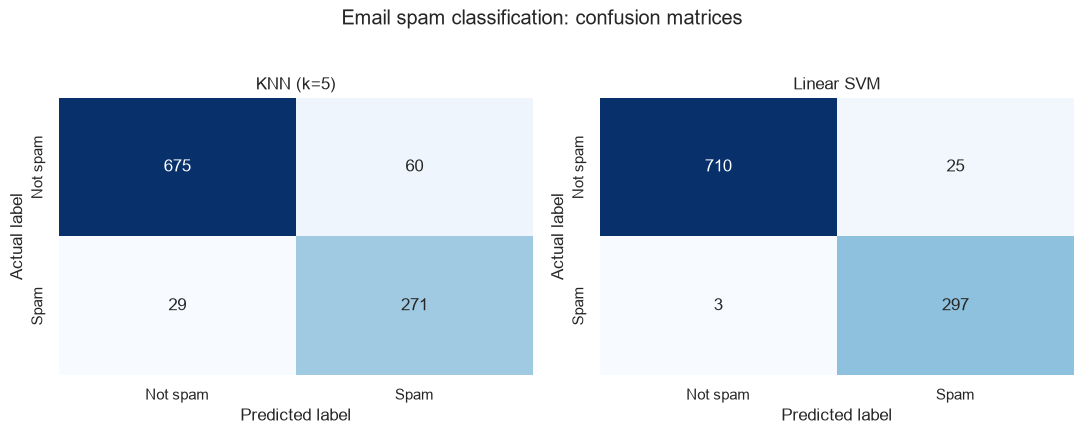

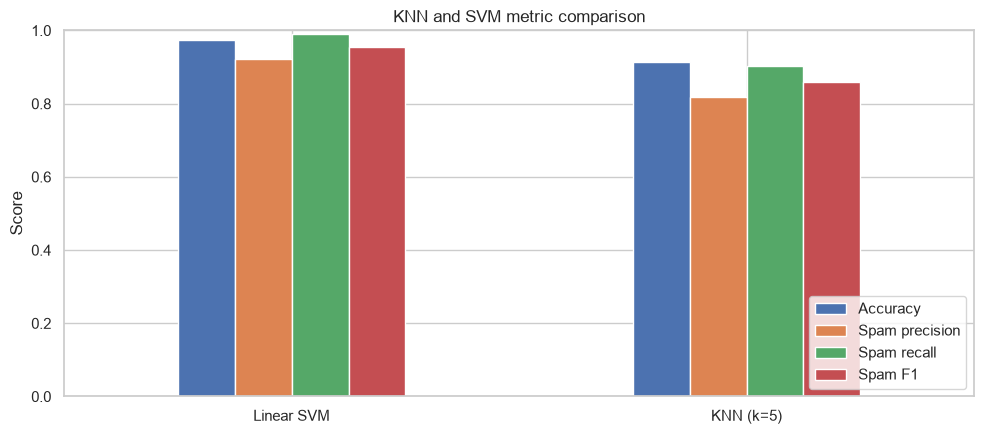

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Not spam", "Spam"], yticklabels=["Not spam", "Spam"]
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
fig.suptitle("Email spam classification: confusion matrices", y=1.03)
plt.tight_layout()
plt.show()

results[["Accuracy", "Spam precision", "Spam recall", "Spam F1"]].plot(
    kind="bar", figsize=(10, 4.5), ylim=(0, 1), rot=0
)
plt.title("KNN and SVM metric comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Conclusion

Use the metric table and confusion matrices to select a model. For spam filtering, recall is useful when missed spam is costly, while precision matters when incorrectly flagging a normal email is costly. The target labels are 0 (not spam) and 1 (spam).

In [7]:
best_model = results["Spam F1"].idxmax()
print("Best model by spam F1-score:", best_model)
print("Its spam F1-score:", round(results.loc[best_model, "Spam F1"], 4))
print(
    "Compare spam recall and precision alongside accuracy before choosing a model; "
    "the class distribution is not perfectly balanced."
)

Best model by spam F1-score: Linear SVM
Its spam F1-score: 0.955
Compare spam recall and precision alongside accuracy before choosing a model; the class distribution is not perfectly balanced.
